In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv('data_for_model_traning.csv',index_col=False)

In [4]:
df_=df.drop(df.columns[0],axis=1)

In [5]:
df_

,views,add_to_cart,unique_item_viewed,session_duration_min,month,day,hour
0,3,0,3,5.462267,9,4,20
1,1,0,1,0.000000,6,4,18
2,1,0,1,0.000000,7,1,18
3,3,0,3,17.695433,7,4,20
4,1,0,1,0.000000,7,2,20
...,...,...,...,...,...,...,...
1761670,1,0,1,0.000000,5,3,23
1761671,1,0,1,0.000000,5,4,0
1761672,1,0,1,0.000000,5,6,3
1761673,1,0,1,0.000000,5,6,18


In [6]:
df['session_duration_min'].describe()

count    1.761675e+06
mean     1.754057e+00
std      8.325496e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      7.284041e+02
Name: session_duration_min, dtype: float64

In [7]:
df.isnull().sum()

Unnamed: 0              0
views                   0
add_to_cart             0
unique_item_viewed      0
session_duration_min    0
month                   0
day                     0
hour                    0
dtype: int64

In [8]:
df_t=pd.read_csv('target_data.csv',index_col=False)

In [9]:
df_t=df_t.drop(df_t.columns[0],axis=1)

In [10]:
df_t.value_counts()

target
0         1747378
1           14297
Name: count, dtype: int64

In [11]:
df_t

,target
0,0
1,0
2,0
3,0
4,0
...,...
1761670,0
1761671,0
1761672,0
1761673,0


# EDA

<Axes: xlabel='target'>

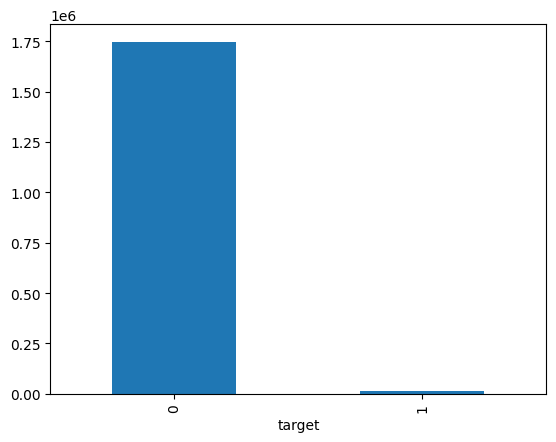

In [12]:
df_t['target'].value_counts().plot(
    kind='bar'
)

## our data is very unbalanced , heavy skewed towards 0

In [34]:
df= df_.join(df_t)

In [14]:
df

,views,add_to_cart,unique_item_viewed,session_duration_min,month,day,hour,target
0,3,0,3,5.462267,9,4,20,0
1,1,0,1,0.000000,6,4,18,0
2,1,0,1,0.000000,7,1,18,0
3,3,0,3,17.695433,7,4,20,0
4,1,0,1,0.000000,7,2,20,0
...,...,...,...,...,...,...,...,...
1761670,1,0,1,0.000000,5,3,23,0
1761671,1,0,1,0.000000,5,4,0,0
1761672,1,0,1,0.000000,5,6,3,0
1761673,1,0,1,0.000000,5,6,18,0


In [15]:
df.groupby('target')[
    [
        'views',
        'add_to_cart',
        'unique_item_viewed',
        'session_duration_min'
        
    ]
].mean()

,views,add_to_cart,unique_item_viewed,session_duration_min
target,,,,
0,1.473634,0.027190,1.297920,1.532963
1,6.247255,1.526194,4.393719,28.776160


In [16]:
df['add_to_cart'].describe()

count    1.761675e+06
mean     3.935573e-02
std      3.995581e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.140000e+02
Name: add_to_cart, dtype: float64

In [17]:
1.140000e+02

114.0

In [18]:
df['has_add_to_cart']=df['add_to_cart'].apply(lambda x: 1 if x>=1 else 0)

In [19]:
a_c=df.groupby('has_add_to_cart')['target'].mean().mul(100)

<Axes: xlabel='has_add_to_cart', ylabel='purches'>

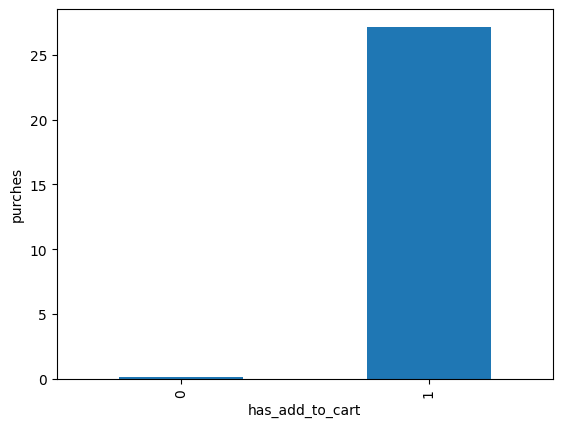

In [20]:
a_c.plot(
    kind='bar',
    ylabel='purches'
)

### means if visitor is not doing add to cart then its only 0.13% chance that he will purches and also if visitor is doing add to cart then there is 27% chance that he will purches some thing

In [21]:
df['duration_bucket']=pd.cut(
    df['session_duration_min'],
    bins=[-1,1,5,10,20,30,40,50,60,70,90,100,120,np.inf],
    labels=[
        '0-1',
        '1-5',
        '5-10',
        '10-20',
        '20-30',
        '30-40',
        '40-50',
        '50-60',
        '60-70',
        '70-90',
        '90-100',
        '100-120',
        '120+'
    ]
)

In [22]:
d_c=df.groupby('duration_bucket')['target'].mean().mul(100)

/var/folders/4k/v2tjslys5277mrnwty__h31h0000gn/T/ipykernel_856/1240628991.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d_c=df.groupby('duration_bucket')['target'].mean().mul(100)


<Axes: xlabel='duration_bucket'>

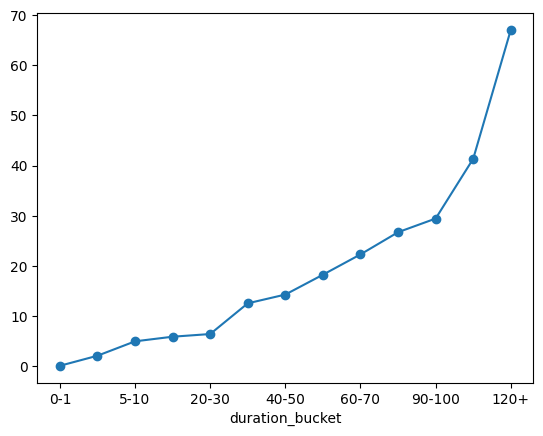

In [23]:
d_c.plot(
    kind='line',
    marker='o'
)

### we got to know that as duration increase the purches rate is also increasing

In [24]:
h_c=df.groupby('hour')['target'].mean().mul(100)

<Axes: xlabel='hour'>

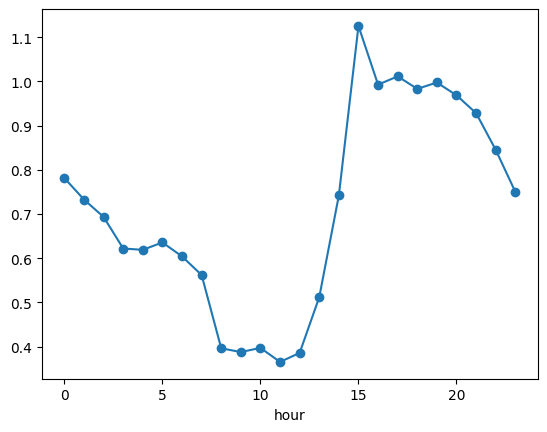

In [25]:
h_c.plot(
    kind='line',
    marker='o'
)

### we got to know that at 15hour(ie 3pm) we have our highest purches rate (ie 1.125482%)

In [26]:
dd_c=df.groupby('day')['target'].mean().mul(100)

In [27]:
dd_c[2]

np.float64(0.9418853795695702)

<Axes: xlabel='day'>

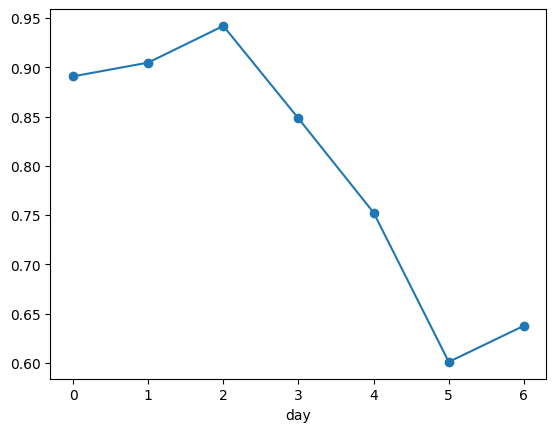

In [28]:
dd_c.plot(
    kind='line',
    marker='o'
)

### means day2 (ie wenseday) has highest purches rate 

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1761675 entries, 0 to 1761674
Data columns (total 8 columns):
 #   Column                Dtype  
---  ------                -----  
 0   views                 int64  
 1   add_to_cart           int64  
 2   unique_item_viewed    int64  
 3   session_duration_min  float64
 4   month                 int64  
 5   day                   int64  
 6   hour                  int64  
 7   target                int64  
dtypes: float64(1), int64(7)
memory usage: 107.5 MB


In [36]:
df.corr()

,views,add_to_cart,unique_item_viewed,session_duration_min,month,day,hour,target
views,1.000000,0.325659,0.950020,0.773898,-0.017529,-0.004134,0.008396,0.182066
add_to_cart,0.325659,1.000000,0.301379,0.383080,-0.000197,-0.005589,0.008167,0.336599
unique_item_viewed,0.950020,0.301379,1.000000,0.724984,-0.014018,-0.003375,0.008627,0.157381
session_duration_min,0.773898,0.383080,0.724984,1.000000,-0.005732,-0.007785,0.015820,0.293588
month,-0.017529,-0.000197,-0.014018,-0.005732,1.000000,0.000744,0.002658,-0.002720
day,-0.004134,-0.005589,-0.003375,-0.007785,0.000744,1.000000,-0.023753,-0.011756
hour,0.008396,0.008167,0.008627,0.015820,0.002658,-0.023753,1.000000,0.012386
target,0.182066,0.336599,0.157381,0.293588,-0.002720,-0.011756,0.012386,1.000000


In [37]:
import seaborn as sns

<Axes: >

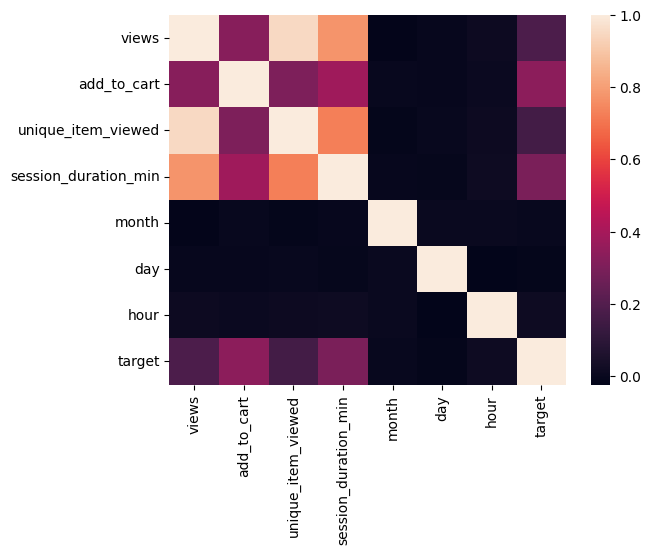

In [38]:
sns.heatmap(df.corr())

### we can see that features have less correlation between them and almost they are independent